In [99]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
df = pd.read_csv(r"D:\Master Uni Marburg\2nd Term Summer 25\NLP\Project\track-a.csv")
df.head()

,id,text,anger,fear,joy,sadness,surprise
0,eng_train_track_a_00001,"Colorado, middle of nowhere.",0,1,0,0,1
1,eng_train_track_a_00002,This involved swimming a pretty large lake tha...,0,1,0,0,0
2,eng_train_track_a_00003,It was one of my most shameful experiences.,0,1,0,1,0
3,eng_train_track_a_00004,"After all, I had vegetables coming out my ears...",0,0,0,0,0
4,eng_train_track_a_00005,Then the screaming started.,0,1,0,1,1


In [101]:
emotion_counts = {
    'anger': df['anger'].sum(),
    'fear': df['fear'].sum(),
    'joy': df['joy'].sum(),
    'sadness': df['sadness'].sum(),
    'surprise': df['surprise'].sum()
}

total_entries = len(df)

# Calculating percentages
emotion_percentages = {emotion: (count/total_entries)*100 for emotion, count in emotion_counts.items()}

print("Emotion Distribution Analysis")
print("="*30)
print(f"Total entries: {total_entries}\n")

print("Absolute counts:")
for emotion, count in emotion_counts.items():
    print(f"{emotion.capitalize()}: {count}")

print("\nPercentages:")
for emotion, percentage in emotion_percentages.items():
    print(f"{emotion.capitalize()}: {percentage:.2f}%")

Emotion Distribution Analysis
Total entries: 2768

Absolute counts:
Anger: 333
Fear: 1611
Joy: 674
Sadness: 878
Surprise: 839

Percentages:
Anger: 12.03%
Fear: 58.20%
Joy: 24.35%
Sadness: 31.72%
Surprise: 30.31%


C:\Users\ASUS\AppData\Local\Temp\ipykernel_7780\3486745014.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_counts.index, y=label_counts.values, palette='deep')


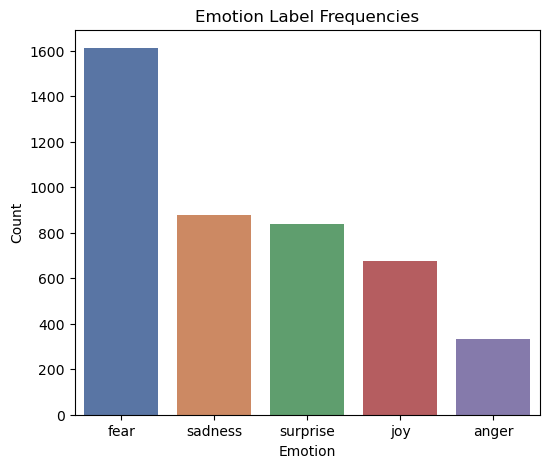

In [103]:
emotion_cols = ['anger', 'fear', 'joy', 'sadness', 'surprise']
label_counts = df[emotion_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(6, 5))
sns.barplot(x=label_counts.index, y=label_counts.values, palette='deep')
plt.title("Emotion Label Frequencies")
plt.ylabel("Count")
plt.xlabel("Emotion")
plt.show()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_7780\3429398120.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=multilabel_sentences.index, y=multilabel_sentences.values, palette = 'deep')


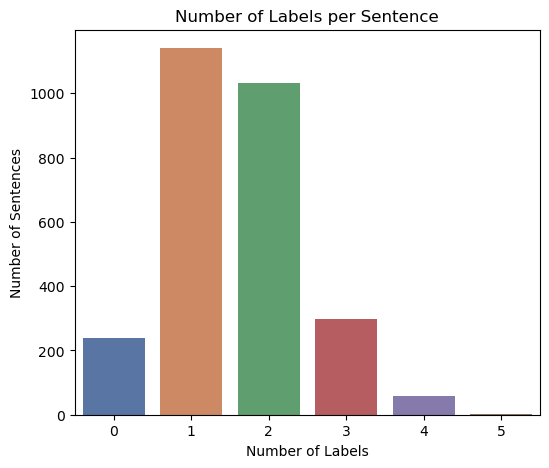

In [105]:
# Count how many labels each sentence has
df["num_labels"] = df[emotion_cols].sum(axis = 1)
multilabel_sentences = df["num_labels"].value_counts().sort_index()

plt.figure(figsize=(6, 5))
sns.barplot(x=multilabel_sentences.index, y=multilabel_sentences.values, palette = 'deep')
plt.title("Number of Labels per Sentence")
plt.xlabel("Number of Labels")
plt.ylabel("Number of Sentences")
plt.show()

count    2768.000000
mean       15.477601
std        10.856667
min         1.000000
25%         8.000000
50%        13.000000
75%        20.000000
max        89.000000
Name: token_count, dtype: float64


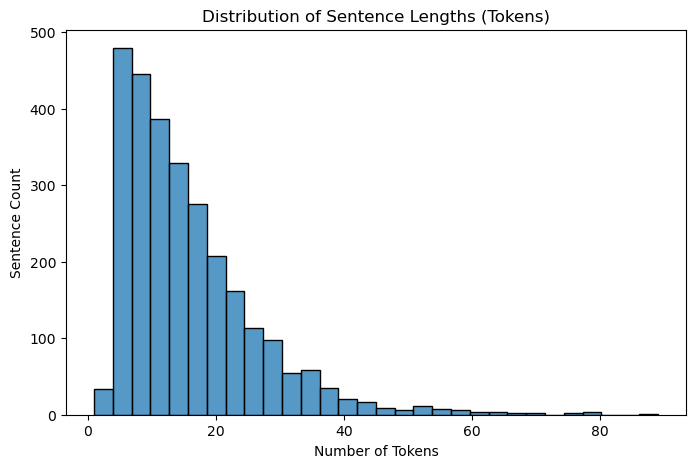

In [107]:
df["token_count"] = df["text"].apply(lambda x: len(str(x).split()))
print(df["token_count"].describe())

# Plot sentence length distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["token_count"], bins=30, kde=False)
plt.title("Distribution of Sentence Lengths (Tokens)")
plt.xlabel("Number of Tokens")
plt.ylabel("Sentence Count")
plt.show()

In [109]:
import string
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer


# Downloading necessary NLTK resources
#nltk.download('punkt_tab')
#nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

def preprocess(text):
    #Lowercasing
    text = text.lower()

    #Tokenizing
    tokens = word_tokenize(text)

    # Removing punctuation and stopwords, then stemming
    tokens = [stemmer.stem(word) for word in tokens if word not in string.punctuation and word not in stop_words]
    return " ".join(tokens)

df["processed_text"] = df["text"].apply(preprocess)
